# TPS · Módulo 3 — Mapas topográficos y análisis estadístico
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Caracterización de la carga cognitiva mediante análisis espectral del EEG durante aritmética mental*

El Módulo 2 dejó la potencia por banda (delta/theta/alfa/beta) de cada sujeto, canal y condición. Acá:

1. Armamos las **métricas** que vamos a comparar: potencia absoluta y relativa por banda, y los índices **theta/alfa** y **theta/beta** (indicadores de carga cognitiva).
2. Hacemos **mapas topográficos** del cuero cabelludo para ver *dónde* cambia cada métrica entre reposo y tarea.
3. *(Parte 2)* **Estadística**: Wilcoxon pareado reposo vs. tarea, Mann-Whitney entre grupos de desempeño (G vs. B) y corrección FDR.

## 0. Carga
Necesita `modulo2_potencias.csv` (salida del Módulo 2) y `modulo1_sujetos.csv` (tabla de sujetos con el grupo G/B, salida del Módulo 1). Si se corre en una sesión nueva de Colab, primero hay que correr los Módulos 1 y 2, o subir esos dos archivos.

In [1]:
!pip -q install mne
import numpy as np, pandas as pd, matplotlib.pyplot as plt, mne
mne.set_log_level('ERROR')

pot  = pd.read_csv('modulo2_potencias.csv')            # sujeto, condicion, canal, banda, potencia, potencia_rel
info = pd.read_csv('modulo1_sujetos.csv')              # Subject, ..., grupo (G/B)
CANALES = ['Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'Fz', 'C3', 'C4', 'Cz',
           'P3', 'P4', 'Pz', 'O1', 'O2', 'T3', 'T4', 'T5', 'T6']       # mismo orden que en los Módulos 1 y 2
BANDAS = {'delta': (0.5, 4), 'theta': (4, 8), 'alfa': (8, 13), 'beta': (13, 30)}
print(pot.shape, '·', pot.sujeto.nunique(), 'sujetos ·', info.grupo.value_counts().to_dict())


[notice] A new release of pip is available: 23.3.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
(5472, 6) · 36 sujetos · {'G': 26, 'B': 10}


## 1. Métricas por sujeto, canal y condición
### 1.1 Potencia absoluta y relativa
El Módulo 2 entrega la **potencia de cada banda en µV²** (PSD de Welch integrada en la banda). A partir de ella armamos una tabla con una fila por sujeto, condición y canal, y calculamos la **potencia relativa**: la fracción de la potencia total entre 0,5 y 30 Hz que cae en cada banda. La relativa permite comparar sujetos sin que la amplitud propia de cada uno (que varía mucho) tape las diferencias.

In [2]:
# Tabla ancha: una fila por (sujeto, condición, canal) y una columna por banda (potencia en µV²)
m = pot.pivot_table(index=['sujeto', 'condicion', 'canal'], columns='banda', values='potencia').reset_index()
m.columns.name = None
total = m[list(BANDAS)].sum(axis=1)
for b in BANDAS:
    m[f'rel_{b}'] = m[b] / total                                       # potencia relativa (fracción de 0,5-30 Hz)
m.groupby('condicion')[[f'rel_{b}' for b in BANDAS]].mean().round(3)

,rel_delta,rel_theta,rel_alfa,rel_beta
condicion,,,,
reposo,0.455,0.143,0.288,0.114
tarea,0.506,0.152,0.226,0.116


### 1.2 Índices de carga cognitiva
- **theta/alfa**: durante el cálculo mental se espera que theta suba (frontal, línea media) y alfa baje (parietal-occipital), así que el cociente debería **aumentar** con la carga. Junta los dos efectos en un solo número.
- **theta/beta**: se usa como índice de atención/control ejecutivo. Lo incluimos porque estaba en el anteproyecto.

Los cocientes de potencia tienen distribución muy asimétrica (un sujeto con alfa muy baja dispara el cociente), por eso los trabajamos en **log₁₀**: así un aumento al doble y una caída a la mitad quedan a la misma distancia del 0, y el promedio entre sujetos no lo dominan unos pocos valores extremos.

In [3]:
m['theta_alfa'] = np.log10(m.theta / m.alfa)
m['theta_beta'] = np.log10(m.theta / m.beta)
m['abs_alfa']   = np.log10(m.alfa)                                    # potencia absoluta de alfa en log (µV²)
m = m.merge(info[['Subject', 'grupo']], left_on='sujeto', right_on='Subject').drop(columns='Subject')

METRICAS = {'rel_delta': 'Delta relativa', 'rel_theta': 'Theta relativa', 'rel_alfa': 'Alfa relativa',
            'rel_beta': 'Beta relativa', 'theta_alfa': 'log θ/α', 'theta_beta': 'log θ/β'}
m.groupby('condicion')[list(METRICAS)].mean().round(3)

,rel_delta,rel_theta,rel_alfa,rel_beta,theta_alfa,theta_beta
condicion,,,,,,
reposo,0.455,0.143,0.288,0.114,-0.263,0.106
tarea,0.506,0.152,0.226,0.116,-0.131,0.127


### 1.3 Diferencia tarea − reposo por sujeto
Como cada sujeto tiene las dos condiciones, la comparación natural es **pareada**: restamos tarea − reposo dentro de cada sujeto y canal. Así se cancela la amplitud propia de cada persona (que varía mucho entre sujetos) y queda sólo el efecto de la tarea. Estas diferencias son lo que se grafica en los mapas y lo que va a usar el test de Wilcoxon.

In [4]:
ancha = m.pivot_table(index=['sujeto', 'grupo', 'canal'], columns='condicion', values=list(METRICAS))
dif = pd.DataFrame({k: ancha[k, 'tarea'] - ancha[k, 'reposo'] for k in METRICAS}).reset_index()   # tarea - reposo

def por_canal(df, col):
    # Promedio de una columna entre sujetos, ordenado como CANALES (formato que pide el topomap)
    return df.groupby('canal')[col].mean().reindex(CANALES).values

dif.groupby('canal')[list(METRICAS)].mean().reindex(CANALES).round(3)

,rel_delta,rel_theta,rel_alfa,rel_beta,theta_alfa,theta_beta
canal,,,,,,
Fp1,0.083,0.004,-0.068,-0.019,0.189,0.118
Fp2,0.054,0.014,-0.058,-0.011,0.175,0.090
F3,0.044,0.020,-0.051,-0.014,0.131,0.091
F4,0.041,0.023,-0.053,-0.011,0.151,0.094
F7,0.046,0.006,-0.046,-0.006,0.128,0.055
F8,0.079,0.000,-0.056,-0.023,0.147,0.094
Fz,0.031,0.028,-0.049,-0.010,0.152,0.108
C3,0.042,0.011,-0.050,-0.004,0.118,0.047
C4,0.027,0.014,-0.045,0.004,0.108,0.017


## 2. Mapas topográficos
Cada mapa interpola los valores de los 19 electrodos sobre la cabeza vista desde arriba (nariz arriba). Usamos el montaje estándar 10-20 de MNE, el mismo del Módulo 1.

### 2.1 Reposo, tarea y diferencia
Para **alfa relativa** y **log θ/α**, que son las métricas centrales de la hipótesis. Reposo y tarea comparten escala de colores para que se puedan comparar a simple vista. La diferencia usa una escala divergente centrada en 0 (rojo = sube con la tarea, azul = baja).

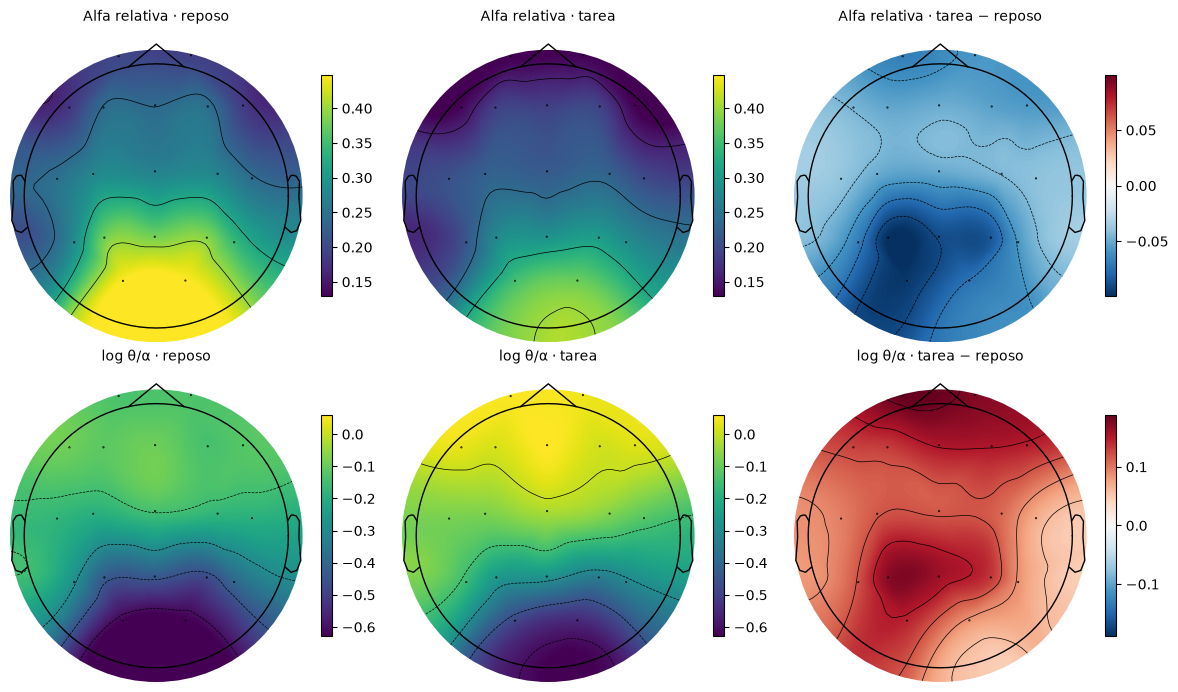

In [5]:
info_mne = mne.create_info(CANALES, 500, 'eeg').set_montage('standard_1020')

def topo(valores, ax, titulo, vlim, cmap='viridis', **kw):
    # Dibuja un mapa topográfico de 19 valores (orden CANALES) con barra de color
    im, _ = mne.viz.plot_topomap(valores, info_mne, axes=ax, show=False, cmap=cmap, vlim=vlim, contours=4, **kw)
    ax.set_title(titulo, fontsize=10)
    plt.colorbar(im, ax=ax, shrink=0.7)

fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for fila, met in zip(ax, ['rel_alfa', 'theta_alfa']):
    medias = {c: por_canal(m[m.condicion == c], met) for c in ('reposo', 'tarea')}
    lim = (min(map(np.min, medias.values())), max(map(np.max, medias.values())))      # escala común reposo/tarea
    for a, c in zip(fila, medias):
        topo(medias[c], a, f'{METRICAS[met]} · {c}', lim)
    d = por_canal(dif, met)
    topo(d, fila[2], f'{METRICAS[met]} · tarea − reposo', (-np.abs(d).max(), np.abs(d).max()), cmap='RdBu_r')
plt.tight_layout()

### 2.2 Diferencia tarea − reposo para todas las métricas
Cada mapa tiene su propia escala simétrica (las métricas tienen unidades distintas), así que lo que se compara entre mapas es **la forma** (dónde está el cambio), no el color absoluto.

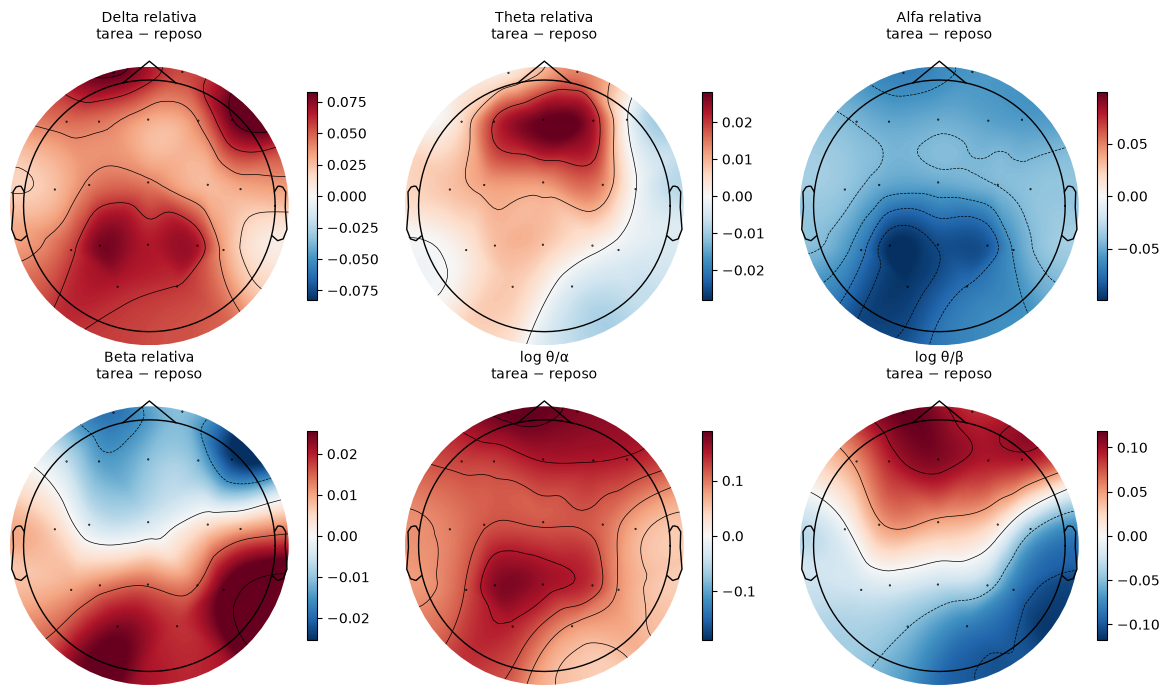

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for a, met in zip(ax.flat, METRICAS):
    d = por_canal(dif, met)
    topo(d, a, f'{METRICAS[met]}\ntarea − reposo', (-np.abs(d).max(), np.abs(d).max()), cmap='RdBu_r')
plt.tight_layout()

### 2.3 Por grupo de desempeño
La misma diferencia de **log θ/α**, separada en buen desempeño (G) y bajo desempeño (B), con una escala común. Es la pregunta del segundo objetivo: ¿el cambio con la tarea es distinto según qué tan bien la hicieron? Que se vea distinto acá no alcanza; lo decide el test de Mann-Whitney de la parte 2.

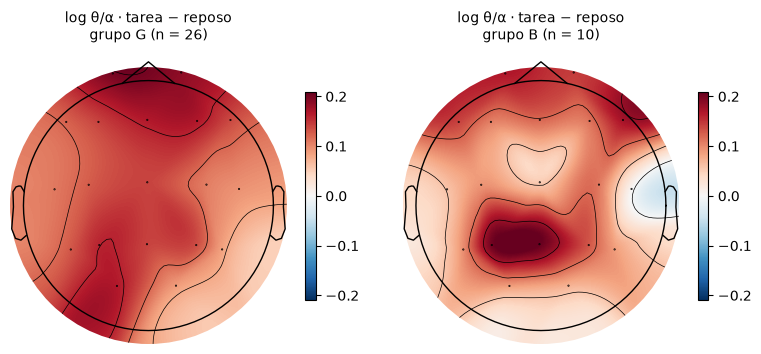

In [7]:
d_grupo = {g: por_canal(dif[dif.grupo == g], 'theta_alfa') for g in ('G', 'B')}
lim = max(np.abs(v).max() for v in d_grupo.values())
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, g in zip(ax, d_grupo):
    n = dif[dif.grupo == g].sujeto.nunique()
    topo(d_grupo[g], a, f'log θ/α · tarea − reposo\ngrupo {g} (n = {n})', (-lim, lim), cmap='RdBu_r')
plt.tight_layout()

### Lectura de los mapas
*(Corrida sobre los 36 sujetos.)*

- **Alfa relativa:** en reposo es máxima en la región parieto-occipital (0,38–0,45), como se espera con ojos cerrados. Con la tarea **cae en todos los canales** (en promedio de 0,288 a 0,226), y la caída es mayor en los **parieto-occipitales: P3 (−0,100), O1 (−0,096) y Pz (−0,089)**. En los centrales y temporales la caída es más chica (C3 −0,050, T3 −0,040).
- **Theta relativa:** el aumento es chico (≈ +0,02) pero se concentra en la región **frontal de la línea media: Fz (+0,028), F4 (+0,023) y F3 (+0,020)**, lo que coincide con la *theta frontal medial* asociada a la carga cognitiva.
- **log θ/α:** **aumenta en todos los canales**, con los mayores cambios en **Fp1 (+0,19), Fp2 (+0,18) y P3 (+0,17)** y los menores en los temporales y occipitales derechos (T4, O2, T6 ≈ +0,07–0,09). Combina el aumento de theta anterior con la caída de alfa posterior, y por eso es el índice que mejor resume el efecto de la tarea.
- **Delta y beta (posibles artefactos):** la delta relativa sube más en **Fp1 (+0,083), F8 (+0,079) y P3 (+0,079)**; Fp2 sube menos (+0,054). El aumento en los frontales (Fp1, F8) puede reflejar movimientos oculares durante el cálculo. La beta sube en **T6, O1 y O2** (+0,02–0,025) y baja en los frontales (F8, Fp1), compatible con actividad muscular posterior. Son los artefactos que el ICA de los autores podría no haber eliminado del todo (ver Módulo 1) y hay que tenerlos en cuenta al interpretar esas bandas.
- **Grupos G vs. B:** en G (n = 26) el aumento de log θ/α es mayor en los **frontales (Fp1, Fp2, F4)**; en B (n = 10), en los **parietales de la línea media (Pz, P3)**. En promedio entre canales el aumento es parecido (G +0,14, B +0,12). Con sólo 10 sujetos en B, esta diferencia visual no alcanza para concluir nada: se evalúa con Mann-Whitney en la parte 2.

In [8]:
m.to_csv('modulo3_metricas.csv', index=False)      # métricas por sujeto/condición/canal (entrada de la parte 2 y del Módulo 4)
dif.to_csv('modulo3_diferencias.csv', index=False)